## Mini-Batch Gradient Descent using DataLoaders

In [1]:
import torch
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
data = fetch_california_housing(as_frame=False)
X = data.data
y = data.target
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [2]:
X_train, X_valid, y_train, y_valid = train_test_split(X_train, y_train, random_state=42)

In [3]:
X_train = torch.FloatTensor(X_train)
X_test = torch.FloatTensor(X_test)
X_valid = torch.FloatTensor(X_valid)
y_train = torch.FloatTensor(y_train).reshape(-1,1)
y_valid = torch.FloatTensor(y_valid).reshape(-1,1)
y_test = torch.FloatTensor(y_test).reshape(-1,1)

In [4]:
n_features = X_train.shape[1] # No. of Features or Columns

In [5]:
from torch import nn
model = nn.Sequential(
    nn.Linear(n_features,50),
    nn.ReLU(),
    nn.Linear(50,50),
    nn.ReLU(),
    nn.Linear(50,1)
)

In [6]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True) # SRS
print(train_dataset[:3])

(tensor([[0.1288, 0.7451, 0.0215, 0.0271, 0.0393, 0.0025, 0.2000, 0.4661],
        [0.6645, 0.4510, 0.0473, 0.0258, 0.0629, 0.0017, 0.1266, 0.6006],
        [0.0808, 0.7843, 0.0214, 0.0231, 0.0239, 0.0015, 0.7000, 0.2719]]), tensor([[2.4140],
        [5.0000],
        [0.6410]]))


In [7]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.manual_seed(42)
model = model.to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.2)
mse = nn.MSELoss()

In [8]:
def train(model, optimizer, criterion, train_loader, n_epochs):
    model.train()
    for epoch in range(n_epochs):
        total_loss = 0.
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = criterion(y_pred, y_batch)
            total_loss += loss.item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

        mean_loss = total_loss / len(train_loader)
        print(f"Epoch {epoch + 1}/{n_epochs}, Loss: {mean_loss:.4f}")

If your dataset size isn't perfectly divisible by the batch_size, the final mini-batch in train_loader will be smaller than the others, leading to an inaccurate average loss calculation.

In [9]:
train(model, optimizer, mse, train_loader, 20)

Epoch 1/20, Loss: 1.0247
Epoch 2/20, Loss: 0.6409
Epoch 3/20, Loss: 0.5899
Epoch 4/20, Loss: 0.5715
Epoch 5/20, Loss: 0.5630
Epoch 6/20, Loss: 0.5452
Epoch 7/20, Loss: 0.5450
Epoch 8/20, Loss: 0.5319
Epoch 9/20, Loss: 0.5338
Epoch 10/20, Loss: 0.5187
Epoch 11/20, Loss: 0.5130
Epoch 12/20, Loss: 0.5154
Epoch 13/20, Loss: 0.5076
Epoch 14/20, Loss: 0.5089
Epoch 15/20, Loss: 0.5111
Epoch 16/20, Loss: 0.4980
Epoch 17/20, Loss: 0.5078
Epoch 18/20, Loss: 0.4948
Epoch 19/20, Loss: 0.4955
Epoch 20/20, Loss: 0.4861


## Evaluation


In [10]:
def evaluate(model, data_loader, metric_func, agrregate_fn=torch.mean):
    model.eval()
    metrics = []
    with torch.no_grad():
        for X_batch,y_batch in data_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            metric = metric_func(y_pred, y_batch)
            metrics.append(metric)
        return agrregate_fn(torch.stack(metrics))

In [11]:
valid_dataset = TensorDataset(X_valid, y_valid)
valid_loader = DataLoader(valid_dataset,batch_size=32)
valid_mse = evaluate(model, valid_loader, mse)
valid_mse

tensor(0.4943, device='cuda:0')

In [12]:
def rmse(y_pred, y_true):
    return ((y_pred - y_true) ** 2).mean().sqrt()
evaluate(model, valid_loader, rmse)

tensor(0.6869, device='cuda:0')

The RMSE should be equal to the square root of the MSE; however, when we compute the square root of the MSE that we found earlier, we get a different result

In [13]:
valid_mse.sqrt()

tensor(0.7030, device='cuda:0')

The reason is that instead of calculating the RMSE over the whole validation set, we computed it over each batch and then computed the mean of all these batch RMSEs. That’s not mathematically equivalent to computing the RMSE over the whole validation set. To solve this, we can use the MSE as our metric_fn, and use the aggregate_fn to compute the square root of the mean MSE:

In [14]:
evaluate(model, valid_loader, mse, agrregate_fn=lambda metrics:torch.sqrt(torch.mean(metrics)))

tensor(0.7030, device='cuda:0')

In [15]:
import torchmetrics

def evaluate_tm(model, data_loader, metric):
    model.eval()
    metric.reset() # resets the metric at start
    for X_batch, y_batch in data_loader:
        X_batch,y_batch = X_batch.to(device), y_batch.to(device)
        y_pred = model(X_batch)
        metric.update(y_pred, y_batch)
    return metric.compute()

c:\Users\TeReX\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Then we can create an RMSE streaming metric, move it to the GPU, and use it to evaluate the validation set

In [16]:
rmse = torchmetrics.MeanSquaredError(squared=False).to(device) #laoding rmse to GPU
evaluate_tm(model, valid_loader, rmse)

tensor(0.7030, device='cuda:0')

In [17]:
def train2(model, optimizer, criterion, data_laoder, valid_loader, metric, n_epochs):
    history = {"train_losses":[],"train_metrics":[],"valid_metrics":[]}
    for epoch in range(n_epochs):
        total_loss = 0.
        metric.reset()
        for X_batch, y_batch in data_laoder:
            model.train()
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = criterion(y_pred, y_batch)
            total_loss += loss.item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            metric.update(y_pred, y_batch)
        mean_loss = total_loss / len(data_laoder)
        history["train_losses"].append(mean_loss)
        history["train_metrics"].append(metric.compute().item())
        history["valid_metrics"].append(evaluate_tm(model, valid_loader, metric).item())
        print(f"Epoch {epoch + 1}/{n_epochs}, "
              f"train loss: {history['train_losses'][-1]:.4f}, "
              f"train metric: {history['train_metrics'][-1]:.4f}, "
              f"valid metric: {history['valid_metrics'][-1]:.4f}")
    return history

model = nn.Sequential(
    nn.Linear(n_features,50), nn.ReLU(),
    nn.Linear(50,40), nn.ReLU(),
    nn.Linear(40,30), nn.ReLU(),
    nn.Linear(30,1)
)
model.to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0)
mse = nn.MSELoss()
rmse = torchmetrics.MeanSquaredError(squared=False).to(device)
history = train2(model, optimizer, mse, train_loader, valid_loader, rmse, 20)


Epoch 1/20, train loss: 1.3632, train metric: 1.1676, valid metric: 1.0606
Epoch 2/20, train loss: 0.7501, train metric: 0.8661, valid metric: 0.7749
Epoch 3/20, train loss: 0.5643, train metric: 0.7512, valid metric: 0.7432
Epoch 4/20, train loss: 0.5456, train metric: 0.7387, valid metric: 0.7322
Epoch 5/20, train loss: 0.5304, train metric: 0.7283, valid metric: 0.7224
Epoch 6/20, train loss: 0.5194, train metric: 0.7207, valid metric: 0.7193
Epoch 7/20, train loss: 0.5147, train metric: 0.7174, valid metric: 0.7112
Epoch 8/20, train loss: 0.5098, train metric: 0.7140, valid metric: 0.7110
Epoch 9/20, train loss: 0.5006, train metric: 0.7075, valid metric: 0.7144
Epoch 10/20, train loss: 0.5001, train metric: 0.7072, valid metric: 0.7010
Epoch 11/20, train loss: 0.4960, train metric: 0.7043, valid metric: 0.7141
Epoch 12/20, train loss: 0.4977, train metric: 0.7055, valid metric: 0.6985
Epoch 13/20, train loss: 0.4910, train metric: 0.7007, valid metric: 0.7186
Epoch 14/20, train lo

In [18]:
history['train_metrics'][:20]

[1.167563557624817,
 0.8660702109336853,
 0.7511901259422302,
 0.7386547327041626,
 0.7283012270927429,
 0.720713198184967,
 0.7174440622329712,
 0.7139757871627808,
 0.7075440287590027,
 0.7072045803070068,
 0.7042999863624573,
 0.7054863572120667,
 0.7006996273994446,
 0.6999329328536987,
 0.6960989236831665,
 0.6961415410041809,
 0.6964696645736694,
 0.6929304003715515,
 0.6938275694847107,
 0.6915727853775024]

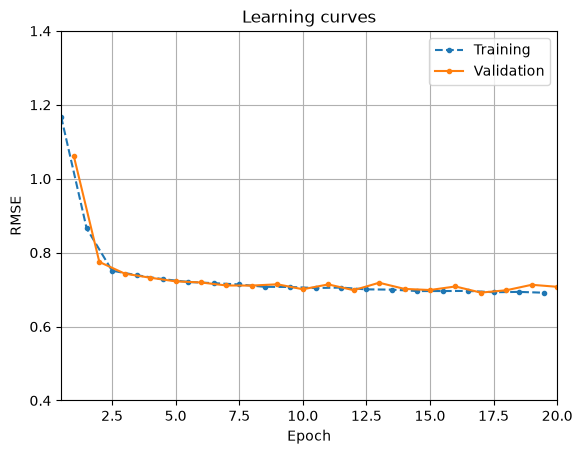

In [19]:
import matplotlib.pyplot as plt
import numpy as np
plt.plot(np.arange(20) + 0.5, history["train_metrics"][:20], ".--",
         label="Training")
plt.plot(np.arange(20) + 1.0, history["valid_metrics"][:20], ".-",
         label="Validation")
plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.grid()
plt.title("Learning curves")
plt.axis([0.5, 20, 0.4, 1.40])
plt.legend()
plt.show()

## Building Nonsequential Models Using Custom Modules

In [20]:
class WideAndDeep(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.deep_stack = nn.Sequential(
            nn.Linear(n_features, 50), nn.ReLU(),
            nn.Linear(50, 40), nn.ReLU(),
        )
        self.output_layer = nn.Linear(n_features+40,1)
    def forward(self, X):
        deep_output = self.deep_stack(X)
        wide_and_deep = torch.concat([X, deep_output],dim=1)
        return self.output_layer(wide_and_deep)

In [33]:
torch.manual_seed(42)
model = WideAndDeep(n_features).to(device)
learning_rate = 0.002
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate, momentum=0)
mse = nn.MSELoss()
rmse = torchmetrics.MeanSquaredError(squared=False).to(device)
history = train2(model, optimizer, mse, train_loader, valid_loader, rmse, 20)

Epoch 1/20, train loss: 1.7015, train metric: 1.3044, valid metric: 1.1337
Epoch 2/20, train loss: 1.2043, train metric: 1.0974, valid metric: 1.1019
Epoch 3/20, train loss: 1.1371, train metric: 1.0664, valid metric: 1.0683
Epoch 4/20, train loss: 1.0670, train metric: 1.0330, valid metric: 1.0320
Epoch 5/20, train loss: 0.9907, train metric: 0.9953, valid metric: 0.9896
Epoch 6/20, train loss: 0.9058, train metric: 0.9517, valid metric: 0.9408
Epoch 7/20, train loss: 0.8137, train metric: 0.9021, valid metric: 0.8882
Epoch 8/20, train loss: 0.7253, train metric: 0.8516, valid metric: 0.8369
Epoch 9/20, train loss: 0.6537, train metric: 0.8085, valid metric: 0.7993
Epoch 10/20, train loss: 0.6093, train metric: 0.7806, valid metric: 0.7793
Epoch 11/20, train loss: 0.5871, train metric: 0.7662, valid metric: 0.7691
Epoch 12/20, train loss: 0.5767, train metric: 0.7594, valid metric: 0.7638
Epoch 13/20, train loss: 0.5707, train metric: 0.7554, valid metric: 0.7599
Epoch 14/20, train lo

#### Different input along wide stack and deep stack

In [31]:
class WideAndDeepV2(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.deep_stack = nn.Sequential(
            nn.Linear(n_features - 2,50), nn.ReLU(), # features Subtracted from the no. of non selected cols in X_deep 
            nn.Linear(50,40), nn.ReLU(),
            nn.Linear(40,30), nn.ReLU(),
        )
        self.output_layer = nn.Linear(30+5, 1) # Add no. of cols selected in X_wide
    
    def forward(self, X):
        X_wide = X[:, :5]
        X_deep = X[:, 2:]
        deep_output = self.deep_stack(X_deep)
        wide_and_deep = torch.concat([X_wide, deep_output], dim=1)
        return self.output_layer(wide_and_deep)

In [32]:
torch.manual_seed(42)
model = WideAndDeepV2(n_features).to(device)
optimizer = torch.optim.SGD(model.parameters(),lr=0.002,momentum=0)
history = train2(model, optimizer, mse, train_loader, valid_loader, rmse, 20)

Epoch 1/20, train loss: 2.0329, train metric: 1.4258, valid metric: 1.1445
Epoch 2/20, train loss: 1.2437, train metric: 1.1152, valid metric: 1.1284
Epoch 3/20, train loss: 1.2119, train metric: 1.1009, valid metric: 1.1135
Epoch 4/20, train loss: 1.1821, train metric: 1.0872, valid metric: 1.0999
Epoch 5/20, train loss: 1.1540, train metric: 1.0742, valid metric: 1.0864
Epoch 6/20, train loss: 1.1272, train metric: 1.0617, valid metric: 1.0736
Epoch 7/20, train loss: 1.1019, train metric: 1.0497, valid metric: 1.0613
Epoch 8/20, train loss: 1.0776, train metric: 1.0381, valid metric: 1.0498
Epoch 9/20, train loss: 1.0545, train metric: 1.0269, valid metric: 1.0382
Epoch 10/20, train loss: 1.0326, train metric: 1.0162, valid metric: 1.0271
Epoch 11/20, train loss: 1.0111, train metric: 1.0055, valid metric: 1.0167
Epoch 12/20, train loss: 0.9907, train metric: 0.9954, valid metric: 1.0060
Epoch 13/20, train loss: 0.9716, train metric: 0.9857, valid metric: 0.9962
Epoch 14/20, train lo

In [34]:
class WideAndDeepV3(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.deep_stack = nn.Sequential(
            nn.Linear(n_features - 2,50), nn.ReLU(),
            nn.Linear(50,40), nn.ReLU(),
            nn.Linear(40,30), nn.ReLU(),
        )
        self.output_layer = nn.Linear(30+5,1)

    def forward(self, X_wide, X_deep):
        deep_output = self.deep_stack(X_deep)
        wide_and_deep = torch.concat([X_wide, deep_output], dim=1)
        return self.output_layer(wide_and_deep)

train_data_wd = TensorDataset(X_train[:, :5], X_train[:, 2:], y_train)
train_loader_wd = DataLoader(train_data_wd,batch_size=32, shuffle=True)

valid_data_wd = TensorDataset(X_valid[:,:5], X_valid[:,2:], y_valid)
valid_loader_wd = DataLoader(valid_data_wd, batch_size=32, shuffle=True)

test_data_wd = TensorDataset(X_test[:,:5], X_test[:,2:], y_test)
test_loader_wd = DataLoader(test_data_wd, batch_size=32)


In [ ]:
def eval_multi_in(model, data_loader, metric):
    model.eval()
    metric.reset()
    with torch.no_grad():
        for X_batch_wide, X_batch_deep, y_batch in data_loader:
            X_batch_wide, X_batch_deep, y_batch = X_batch_wide.to(device), X_batch_deep.to(device), y_batch.to(device)
            y_pred = model(X_batch_wide, X_batch_deep)
            metric.update(y_pred, y_batch)
        return metric.compute()

def train_multi_in(model, optimizer, criterion, metric, train_loader, valid_loader, n_epochs):
    history = {"total loss":[],"train metrics":[],"valid metrics":[]}
    for epoch in range(n_epochs):
        total_loss = 0.
        metric.reset()
        for *X_batch_inputs, y_batch in train_loader:
            model.train()
            X_batch_inputs, y_batch = [X.to(device) for X in X_batch_inputs], y_batch.to(device)
            y_pred = model(*X_batch_inputs)
            loss = criterion(y_pred, y_batch)
            total_loss += loss.item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            metric.update(y_pred, y_batch)
        mean_loss = total_loss / len(train_loader)
        history["total loss"].append(mean_loss)
        history["train metrics"].append(metric.compute().item())
        history["valid metrics"].append(eval_multi_in(model,valid_loader,metric).item())
        print(f'Epoch: {epoch+1}/{n_epochs}, ' 
              f'Train loss: {history["total loss"][-1]:.4f}, '
              f'Train metric: {history["train metrics"][-1]:.4f}, '
              f'Valid metric: {history["valid metrics"][-1]:.4f}, ')
    return history

torch.manual_seed(42)
model = WideAndDeepV3(n_features).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr= 0.01, momentum=0)
mse = nn.MSELoss()
rmse = torchmetrics.MeanSquaredError(squared=False).to(device)

In [43]:
history = train_multi_in(model, optimizer, mse, rmse, train_loader_wd, valid_loader_wd, 20)

Epoch: 1/20, Train loss: 1.3713, Train metric: 1.1710, Valid metric: 1.0881, 
Epoch: 2/20, Train loss: 1.0802, Train metric: 1.0393, Valid metric: 1.0273, 
Epoch: 3/20, Train loss: 0.9736, Train metric: 0.9867, Valid metric: 0.9776, 
Epoch: 4/20, Train loss: 0.8873, Train metric: 0.9420, Valid metric: 0.9335, 
Epoch: 5/20, Train loss: 0.8108, Train metric: 0.9005, Valid metric: 0.8912, 
Epoch: 6/20, Train loss: 0.7354, Train metric: 0.8576, Valid metric: 0.8429, 
Epoch: 7/20, Train loss: 0.6552, Train metric: 0.8095, Valid metric: 0.8031, 
Epoch: 8/20, Train loss: 0.5859, Train metric: 0.7655, Valid metric: 0.7564, 
Epoch: 9/20, Train loss: 0.5550, Train metric: 0.7450, Valid metric: 0.7377, 
Epoch: 10/20, Train loss: 0.5394, Train metric: 0.7344, Valid metric: 0.7364, 
Epoch: 11/20, Train loss: 0.5318, Train metric: 0.7293, Valid metric: 0.7540, 
Epoch: 12/20, Train loss: 0.5187, Train metric: 0.7202, Valid metric: 0.7250, 
Epoch: 13/20, Train loss: 0.5141, Train metric: 0.7170, Valid

In [45]:
class WideAndDeepDataset(torch.utils.data.Dataset):
    def __init__(self, X_wide, X_deep, y):
        super().__init__()
        self.X_wide = X_wide
        self.X_deep = X_deep
        self.y = y

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        input_dic = {'X_wide':self.X_wide[idx], 'X_deep':self.X_deep[idx]}
        return input_dic, self.y[idx]

In [46]:
train_data_named = WideAndDeepDataset(
    X_wide=X_train[:, :5], X_deep=X_train[:, 2:], y=y_train)
train_loader_named = DataLoader(train_data_named, batch_size=32, shuffle=True)

valid_data_named = WideAndDeepDataset(
    X_wide=X_valid[:,:5], X_deep=X_valid[:,2:], y=y_valid 
)
valid_loader_named = DataLoader(valid_data_named, batch_size=32)

test_data_named = WideAndDeepDataset(
    X_wide=X_test[:,:5], X_deep=X_test[:,2:], y=y_test
)
test_loader_named = DataLoader(test_data_named, batch_size=32)

In [53]:
a = next(iter(train_loader_named))
len(a)

2

In [54]:
def evaluate_named(model, valid_loader, metric):
    model.eval()
    metric.reset()
    with torch.no_grad():
        for inputs, y_batch in valid_loader:
            inputs = {name: X.to(device) for name,X in inputs.items()}
            y_batch = y_batch.to(device)
            y_pred = model(X_wide=inputs["X_wide"],X_deep=inputs["X_deep"])
            metric.update(y_pred, y_batch)
    return metric.compute()

def train_named(model, optimizer, criterion, metric, train_loader, valid_loader, n_epochs):
    history = {"total loss":[],"train metrics":[],"valid metrics":[]}
    for epoch in range(n_epochs):
        total_loss = 0.
        metric.reset()
        for inputs, y_batch in train_loader:
            model.train()
            inputs, y_batch = {name:X.to(device) for name, X in inputs.items()}, y_batch.to(device)
            y_pred = model(**inputs)
            loss = criterion(y_pred, y_batch)
            total_loss += loss.item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            metric.update(y_pred, y_batch)
        mean_loss = total_loss / len(train_loader)
        history["total loss"].append(mean_loss)
        history["train metrics"].append(metric.compute().item())
        history["valid metrics"].append(evaluate_named(model,valid_loader,metric).item())
        print(f'Epoch: {epoch+1}/{n_epochs}, ' 
              f'Train loss: {history["total loss"][-1]:.4f}, '
              f'Train metric: {history["train metrics"][-1]:.4f}, '
              f'Valid metric: {history["valid metrics"][-1]:.4f}, ')
    return history

In [55]:
history = train_named(model, optimizer, mse, rmse, train_loader_named, valid_loader_named, 20)

Epoch: 1/20, Train loss: 0.4915, Train metric: 0.7011, Valid metric: 0.7036, 
Epoch: 2/20, Train loss: 0.4913, Train metric: 0.7009, Valid metric: 0.7095, 
Epoch: 3/20, Train loss: 0.4903, Train metric: 0.7002, Valid metric: 0.7049, 
Epoch: 4/20, Train loss: 0.4876, Train metric: 0.6983, Valid metric: 0.7029, 
Epoch: 5/20, Train loss: 0.4887, Train metric: 0.6991, Valid metric: 0.7218, 
Epoch: 6/20, Train loss: 0.4841, Train metric: 0.6958, Valid metric: 0.7540, 
Epoch: 7/20, Train loss: 0.4842, Train metric: 0.6958, Valid metric: 0.7001, 
Epoch: 8/20, Train loss: 0.4862, Train metric: 0.6973, Valid metric: 0.6991, 
Epoch: 9/20, Train loss: 0.4849, Train metric: 0.6964, Valid metric: 0.7131, 
Epoch: 10/20, Train loss: 0.4829, Train metric: 0.6949, Valid metric: 0.6990, 
Epoch: 11/20, Train loss: 0.4829, Train metric: 0.6949, Valid metric: 0.7054, 
Epoch: 12/20, Train loss: 0.4830, Train metric: 0.6950, Valid metric: 0.6999, 
Epoch: 13/20, Train loss: 0.4812, Train metric: 0.6937, Valid

In [65]:
class WideAndDeepV4(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.deep_stack = nn.Sequential(
            nn.Linear(n_features-2, 50), nn.ReLU(),
            nn.Linear(50,40), nn.ReLU(),
            nn.Linear(40,30), nn.ReLU(),
        )
        self.output_layer = nn.Linear(30+5,1)
        self.aux_output = nn.Linear(30,1)

    def forward(self, X_deep, X_wide):
        deep_output = self.deep_stack(X_deep)
        wide_and_deep = torch.concat([X_wide, deep_output],dim=1)
        main_output = self.output_layer(wide_and_deep)
        aux_out_layer = self.aux_output(deep_output)
        return main_output, aux_out_layer

def eval_multi_out(model, valid_loader, metric):
    model.eval()
    metric.reset()
    for inputs, y_batch in valid_loader:
        inputs= {name:X.to(device) for name,X in inputs.items()}
        y_batch = y_batch.to(device)
        y_pred, _ = model(**inputs)
        metric.update(y_pred, y_batch)
    return metric.compute()

def train_multi_out(model, optimizer, criterion, metric, train_load, valid_load, n_epochs):
    history = {'train loss':[], 'train metric':[], 'valid metric':[],}
    for epoch in range(n_epochs):
        total_loss = 0.
        metric.reset()
        for inputs, y_batch in train_load:
            model.train()
            inputs, y_batch = {name:X.to(device) for name,X in inputs.items()}, y_batch.to(device)
            y_pred, y_pred_aux = model(**inputs)
            main_loss = criterion(y_pred, y_batch)
            aux_loss = criterion(y_pred_aux, y_batch)
            loss = 0.8 * main_loss + 0.2 * aux_loss 
            total_loss += loss.item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            metric.update(y_pred, y_batch)
        mean_loss = total_loss / len(train_load)
        history['train loss'].append(mean_loss)
        history['train metric'].append(metric.compute().item())
        history['valid metric'].append(eval_multi_out(model, valid_load, metric).item())
        print(f'Epoch: {epoch+1}/{n_epochs}, ' 
              f'Train loss: {history["train loss"][-1]:.4f}, '
              f'Train metric: {history["train metric"][-1]:.4f}, '
              f'Valid metric: {history["valid metric"][-1]:.4f}, '
            )
    return history


In [66]:
model = WideAndDeepV4(n_features).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0)
mse = nn.MSELoss()
rmse = torchmetrics.MeanSquaredError(squared=False).to(device)

history = train_multi_out(model, optimizer, mse, rmse, train_loader_named, valid_loader_named, 20)

Epoch: 1/20, Train loss: 1.5508, Train metric: 1.2033, Valid metric: 1.1031, 
Epoch: 2/20, Train loss: 1.1610, Train metric: 1.0587, Valid metric: 1.0524, 
Epoch: 3/20, Train loss: 1.0851, Train metric: 1.0141, Valid metric: 1.0099, 
Epoch: 4/20, Train loss: 1.0229, Train metric: 0.9764, Valid metric: 0.9736, 
Epoch: 5/20, Train loss: 0.9685, Train metric: 0.9427, Valid metric: 0.9401, 
Epoch: 6/20, Train loss: 0.9180, Train metric: 0.9113, Valid metric: 0.9086, 
Epoch: 7/20, Train loss: 0.8664, Train metric: 0.8798, Valid metric: 0.8719, 
Epoch: 8/20, Train loss: 0.8015, Train metric: 0.8405, Valid metric: 0.8249, 
Epoch: 9/20, Train loss: 0.7224, Train metric: 0.7920, Valid metric: 0.7884, 
Epoch: 10/20, Train loss: 0.6644, Train metric: 0.7566, Valid metric: 0.7572, 
Epoch: 11/20, Train loss: 0.6373, Train metric: 0.7408, Valid metric: 0.7461, 
Epoch: 12/20, Train loss: 0.6248, Train metric: 0.7336, Valid metric: 0.7316, 
Epoch: 13/20, Train loss: 0.6177, Train metric: 0.7292, Valid